# Predicting whether a Netflix title is rated 18+ from its description and genre
Multinomial Naive Bayes on the Kaggle Netflix titles dataset.

## 1. Imports and load data

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import classification_report, ConfusionMatrixDisplay, accuracy_score, f1_score

df = pd.read_csv("netflix_titles.csv")
print(df.shape)
df.head()

(8807, 12)


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 2. Data quality checks (before cleaning)

In [41]:
print("Missing values per column:")
print(df.isnull().sum())
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate descriptions:", df["description"].duplicated().sum())

Missing values per column:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64

Duplicate rows: 0
Duplicate descriptions: 32


In [42]:
print(df["rating"].value_counts(dropna=False))

rating
TV-MA       3207
TV-14       2160
TV-PG        863
R            799
PG-13        490
TV-Y7        334
TV-Y         307
PG           287
TV-G         220
NR            80
G             41
TV-Y7-FV       6
NaN            4
NC-17          3
UR             3
74 min         1
84 min         1
66 min         1
Name: count, dtype: int64


## 3. Cleaning
- Keep only valid age ratings (drops missing ratings, NR/UR unrated titles, and the 3 rows with durations like "74 min" in the rating column)
- Drop missing and duplicate descriptions
- Create the target: **18+** = R, TV-MA, NC-17; everything else = **Not 18+**

In [43]:
valid = ["TV-Y", "TV-Y7", "TV-Y7-FV", "TV-G", "G", "PG", "TV-PG",
         "PG-13", "TV-14", "R", "TV-MA", "NC-17"]

before = len(df)
df = df[df["rating"].isin(valid)]
df = df.dropna(subset=["description", "listed_in"])
df = df.drop_duplicates(subset="description")
print(f"Rows: {before} -> {len(df)} ({before - len(df)} removed)")

df["adult"] = df["rating"].isin(["R", "TV-MA", "NC-17"]).map({True: "18+", False: "Not 18+"})
print(df["adult"].value_counts())

Rows: 8807 -> 8686 (121 removed)
adult
Not 18+    4682
18+        4004
Name: count, dtype: int64


## 4. Combine description and genre into one text feature
Each genre becomes a single token with a `g_` prefix, so "International Movies" stays one feature and genre tokens are kept separate from description words.

In [44]:
def genre_tokens(col):
    # "Dramas, International Movies" -> "g_Dramas g_International_Movies"
    return col.str.split(", ").apply(
        lambda items: " ".join(
            "g_" + x.replace(" ", "_").replace("'", "").replace("-", "_").replace("&", "and")
            for x in items
        )
    )

df["genre_tokens"] = genre_tokens(df["listed_in"])
df["text"] = df["description"] + " " + df["genre_tokens"]

print(df["listed_in"].iloc[0])
print(df["text"].iloc[0])

Documentaries
As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable. g_Documentaries


## 5. Exploratory data analysis

### 5.1 Target distribution

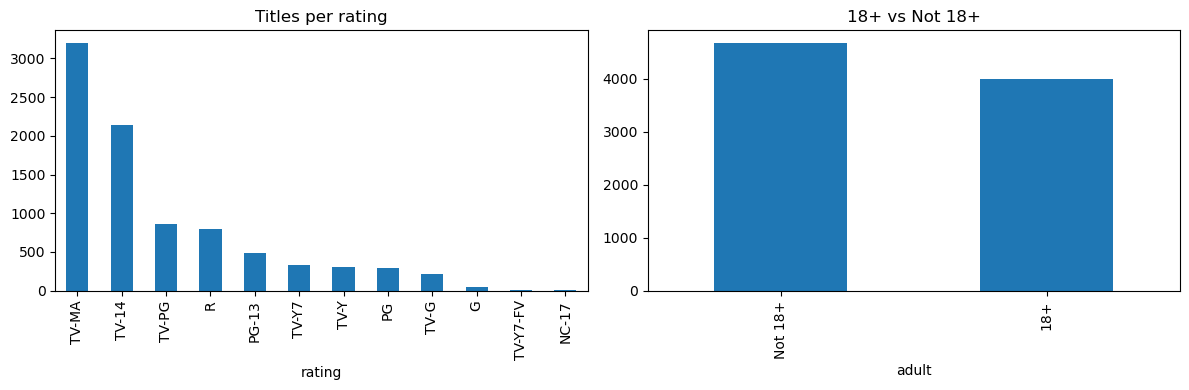

Baseline accuracy (always guess the majority class): 0.539


In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
df["rating"].value_counts().plot(kind="bar", ax=axes[0], title="Titles per rating")
df["adult"].value_counts().plot(kind="bar", ax=axes[1], title="18+ vs Not 18+")
plt.tight_layout()
plt.show()

print("Baseline accuracy (always guess the majority class):",
      round(df["adult"].value_counts(normalize=True).max(), 3))

### 5.2 Description length

count    8686.000000
mean       23.885333
std         2.842595
min        10.000000
25%        22.000000
50%        24.000000
75%        26.000000
max        48.000000
Name: desc_len, dtype: float64
adult
18+        23.9
Not 18+    23.9
Name: desc_len, dtype: float64


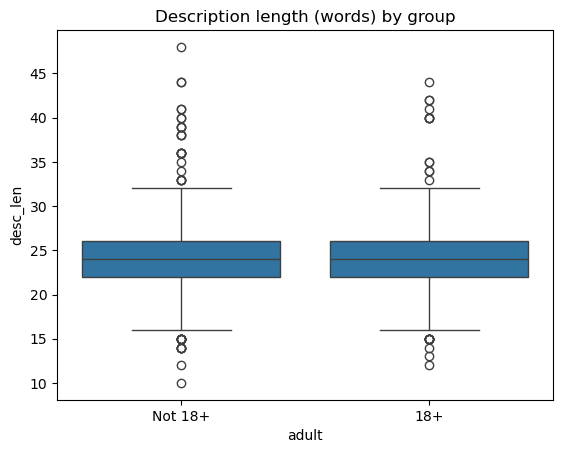

In [46]:
df["desc_len"] = df["description"].str.split().str.len()
print(df["desc_len"].describe())
print(df.groupby("adult")["desc_len"].mean().round(1))

sns.boxplot(data=df, x="adult", y="desc_len")
plt.title("Description length (words) by group")
plt.show()

### 5.3 Most common description words per group

In [47]:
for g in ["18+", "Not 18+"]:
    cv = CountVectorizer(stop_words="english")
    counts = cv.fit_transform(df.loc[df["adult"] == g, "description"]).sum(axis=0).A1
    top = pd.Series(counts, index=cv.get_feature_names_out()).nlargest(15)
    print(g, list(top.index))

18+ ['life', 'young', 'new', 'family', 'man', 'woman', 'world', 'love', 'series', 'documentary', 'friends', 'group', 'takes', 'stand', 'murder']
Not 18+ ['life', 'young', 'new', 'world', 'family', 'love', 'friends', 'man', 'woman', 'series', 'school', 'documentary', 'help', 'father', 'home']


### 5.4 Genre vs 18+
Share of 18+ titles in each genre (genres with at least 100 titles).

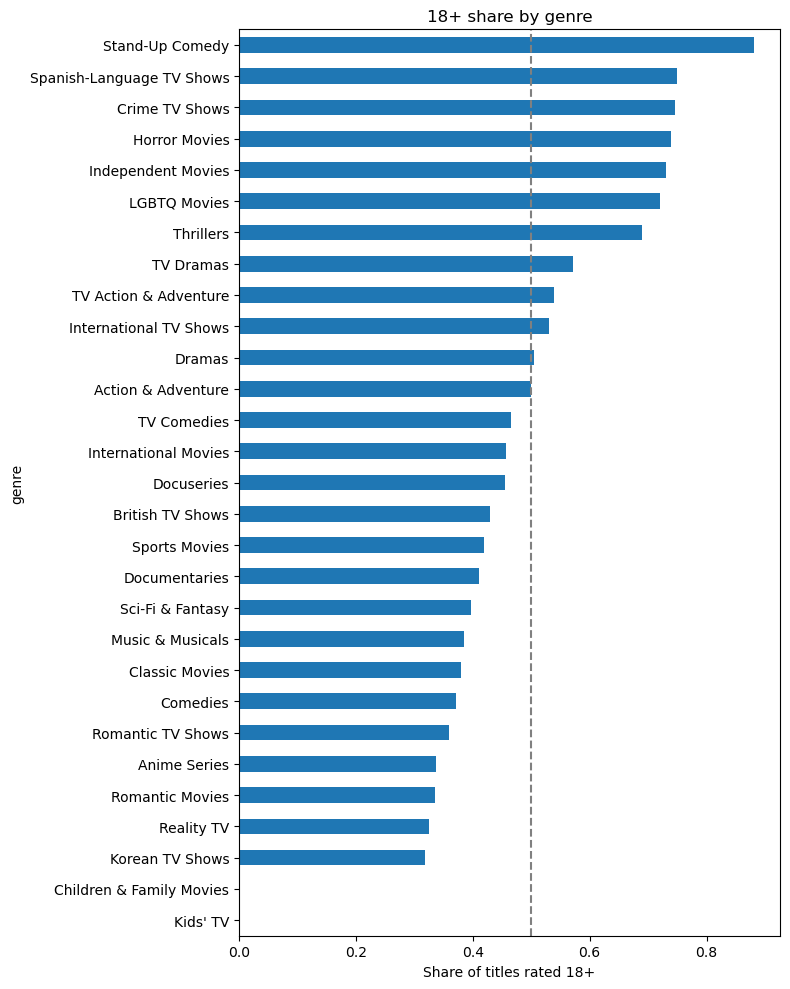

                           pct_18plus     n
genre                                      
Kids' TV                         0.00   448
Children & Family Movies         0.00   639
Korean TV Shows                  0.32   151
Reality TV                       0.33   255
Romantic Movies                  0.34   611
Anime Series                     0.34   175
Romantic TV Shows                0.36   368
Comedies                         0.37  1651
Classic Movies                   0.38   113
Music & Musicals                 0.38   367
Sci-Fi & Fantasy                 0.40   242
Documentaries                    0.41   847
Sports Movies                    0.42   215
British TV Shows                 0.43   251
Docuseries                       0.45   394
International Movies             0.46  2697
TV Comedies                      0.46   579
Action & Adventure               0.50   843
Dramas                           0.50  2386
International TV Shows           0.53  1346
TV Action & Adventure           

In [48]:
genres = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre").reset_index(drop=True)
share = genres.groupby("genre")["adult"].agg(
    pct_18plus=lambda s: (s == "18+").mean(), n="size"
)
share = share[share["n"] >= 100].sort_values("pct_18plus")

share["pct_18plus"].plot(kind="barh", figsize=(8, 10))
plt.axvline(0.5, color="grey", linestyle="--")
plt.xlabel("Share of titles rated 18+")
plt.title("18+ share by genre")
plt.tight_layout()
plt.show()

print(share.round(2))

## 6. Train/test split
Stratified so both sets keep the same 18+ / Not 18+ proportions. The vectorizer is inside the pipeline, so it only learns vocabulary from the training set.

In [49]:
X = df["text"]
y = df["adult"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
print("Train:", len(X_train), " Test:", len(X_test))

Train: 6948  Test: 1738


## 7. Multinomial Naive Bayes (description + genre)
Word counts + Multinomial NB. The token pattern keeps every token, including the genre tags. Alpha (smoothing) is tuned with 5-fold cross-validation on the training set only.

In [50]:
def make_model():
    return make_pipeline(
        CountVectorizer(token_pattern=r"(?u)\b\w+\b"),
        MultinomialNB(),
    )

grid = GridSearchCV(
    make_model(),
    {"multinomialnb__alpha": [0.1, 0.5, 1, 2]},
    scoring="f1_macro",
    cv=5,
)
grid.fit(X_train, y_train)

print("Best alpha:", grid.best_params_)
print("Best cross-validation macro-F1:", round(grid.best_score_, 3))

Best alpha: {'multinomialnb__alpha': 1}
Best cross-validation macro-F1: 0.695


## 8. Evaluation on the test set

Accuracy: 0.708
Macro-F1: 0.707

              precision    recall  f1-score   support

         18+       0.68      0.70      0.69       801
     Not 18+       0.74      0.71      0.72       937

    accuracy                           0.71      1738
   macro avg       0.71      0.71      0.71      1738
weighted avg       0.71      0.71      0.71      1738



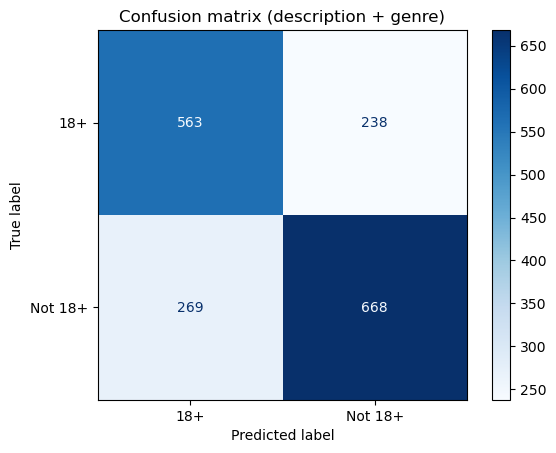

In [51]:
y_pred = grid.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Macro-F1:", round(f1_score(y_test, y_pred, average="macro"), 3))
print()
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=["18+", "Not 18+"], cmap="Blues")
plt.title("Confusion matrix (description + genre)")
plt.show()

## 9. Does genre help? Comparison with description only and genre only
Same split, same model, only the input changes.

In [52]:
inputs = {
    "Description only": df["description"],
    "Genre only": df["genre_tokens"],
    "Description + genre": df["text"],
}

rows = []
for name, X_variant in inputs.items():
    g = GridSearchCV(make_model(), {"multinomialnb__alpha": [0.1, 0.5, 1, 2]},
                     scoring="f1_macro", cv=5)
    g.fit(X_variant[X_train.index], y_train)
    p = g.predict(X_variant[X_test.index])
    rows.append({
        "Input": name,
        "Accuracy": round(accuracy_score(y_test, p), 3),
        "Macro-F1": round(f1_score(y_test, p, average="macro"), 3),
    })

comparison = pd.DataFrame(rows)
baseline = (y_test == y_test.mode()[0]).mean()
print("Baseline accuracy:", round(baseline, 3))
comparison

Baseline accuracy: 0.539


,Input,Accuracy,Macro-F1
0,Description only,0.667,0.666
1,Genre only,0.687,0.677
2,Description + genre,0.708,0.707


## 10. What the model learned
Tokens whose probability is much higher in one group than the other, split into description words and genres.

In [53]:
nb = grid.best_estimator_.named_steps["multinomialnb"]
tokens = np.array(grid.best_estimator_.named_steps["countvectorizer"].get_feature_names_out())
i18 = list(nb.classes_).index("18+")
diff = nb.feature_log_prob_[i18] - nb.feature_log_prob_[1 - i18]   # positive = points to 18+

is_genre = np.char.startswith(tokens.astype(str), "g_")
for label, mask in [("Genres", is_genre), ("Description words", ~is_genre)]:
    t, d = tokens[mask], diff[mask]
    order = np.argsort(d)
    print(f"{label} pointing to 18+:     ", list(t[order[-10:]][::-1]))
    print(f"{label} pointing to Not 18+: ", list(t[order[:10]]))
    print()

Genres pointing to 18+:      ['g_stand_up_comedy', 'g_spanish_language_tv_shows', 'g_crime_tv_shows', 'g_horror_movies', 'g_tv_horror', 'g_independent_movies', 'g_lgbtq_movies', 'g_tv_thrillers', 'g_thrillers', 'g_stand_up_comedy_and_talk_shows']
Genres pointing to Not 18+:  ['g_kids_tv', 'g_children_and_family_movies', 'g_faith_and_spirituality', 'g_science_and_nature_tv', 'g_anime_features', 'g_tv_sci_fi_and_fantasy', 'g_movies', 'g_teen_tv_shows', 'g_korean_tv_shows', 'g_classic_and_cult_tv']

Description words pointing to 18+:      ['comedians', 'sexuality', 'rapper', 'australian', 'spirals', 'boston', 'addict', 'outlaw', 'horror', 'disgraced']
Description words pointing to Not 18+:  ['bheem', 'fairy', 'ninja', 'rainbow', 'pets', 'barbie', 'species', 'dinosaur', 'polar', 'amazing']



## 11. Error analysis
Which original ratings get misclassified most often?

In [54]:
results = df.loc[X_test.index, ["title", "rating", "listed_in", "description"]].copy()
results["true"] = y_test
results["pred"] = y_pred
results["correct"] = results["true"] == results["pred"]

print(results.groupby("rating")["correct"].mean().sort_values().round(2))

rating
NC-17       0.50
TV-14       0.58
PG-13       0.60
TV-MA       0.69
R           0.74
TV-PG       0.76
PG          0.94
TV-G        0.94
G           1.00
TV-Y        1.00
TV-Y7       1.00
TV-Y7-FV    1.00
Name: correct, dtype: float64


In [55]:
# A few misclassified examples
results[~results["correct"]][["title", "rating", "pred", "listed_in", "description"]].head(10)

,title,rating,pred,listed_in,description
6819,Gabriel and the Mountain,TV-MA,Not 18+,"Dramas, Independent Movies, International Movies","In a drama based on a true story, Brazilian ba..."
3132,Dil Dhadakne Do,TV-MA,Not 18+,"Comedies, Dramas, International Movies",While hosting a shipboard holiday for relative...
6554,Dagh Ujala,TV-MA,Not 18+,"Dramas, Independent Movies, International Movies",A lesbian daughter fights off an arranged marr...
5933,The Borgias,TV-MA,Not 18+,TV Dramas,Follow the lives of the notorious Borgia famil...
6145,American Masters: Ted Williams,TV-MA,Not 18+,"Documentaries, Sports Movies",Baseball legend Ted Williams fights to become ...
5439,My Only Love Song,TV-MA,Not 18+,"International TV Shows, Korean TV Shows, Roman...",When things don't go her way during a shooting...
4000,5 Flights Up,PG-13,18+,"Comedies, Dramas, Independent Movies","A couple finds unexpected drama when, after 40..."
4908,Goodnight DJ 1,TV-14,18+,"International TV Shows, TV Dramas, TV Horror",Young radio announcers from varying background...
175,The Blue Lagoon,R,Not 18+,"Dramas, Romantic Movies","Two shipwrecked children, stranded for years o..."
8485,The Right One,TV-14,18+,"Dramas, International Movies, Romantic Movies","Under pressure to marry, a rich playboy is con..."
